# Using my Modelling Code to Make Paper Figures

In [1]:
import os  # noqa: I001
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from ode_model import ode_lotka

filepath = os.path.abspath("")
datadir = f'{filepath}/data/'
figdir = f'{filepath}/figures/'
np.random.seed(42)

## Show Conjugation in a Community without Colonisation Resistance

In [2]:
# --- PARAMETERS FOR NO CR ---

# Number of species to use
n_species = 1                              # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = 0                           # community connectivty (probability of interactions)
sigma = 1e-5                               # interspecies interaction strength standard deviation
P_m = 0                                    # proportion of species reactions that are positive
self_inhibition = 0.1                      # intra-specific interaction strength

# Parameters for the model
conjugation_rate = 5e-4                    # average plasmid conjugation rate

# Parameters at the start of the model
t_start = 0                                # starting timestep
t_end = 100                               # ending timestep
x0 = [5e-5, 5e-5, 0, 1]                      # starting population size

### Modelling Different Selections

#### Modelling a simple 1-species community that provides no colonisation resistance and no antibiotic
This is showing that the donor and recipient are able to grow to carrying capacity and transconjugants are able to form.

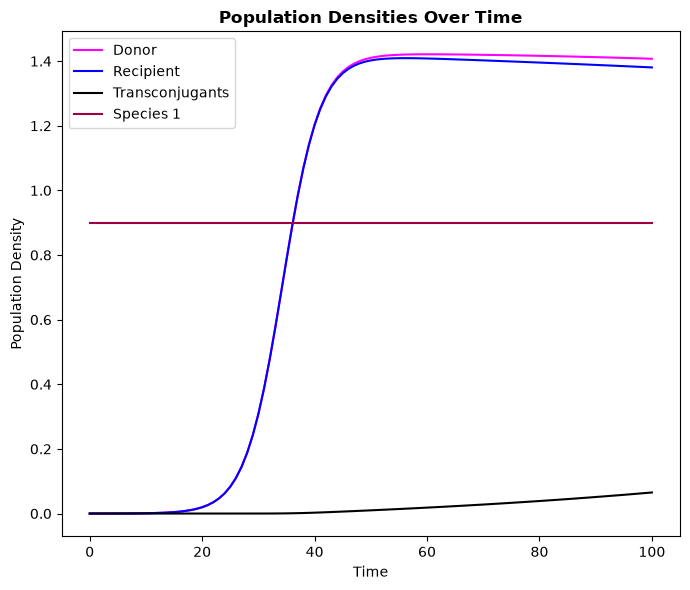

In [3]:
# --- SUSCEPTIBILITY ADJUSTMENTS FOR MODEL ---
susceptibility = [0.05, 0.05, 0.05, 0.05]      # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0                             # magnitude of perturbation, between 0 and 1

# --- MODEL FOR NO CR ---
no_cr_t = []
no_cr_trans = []
repeats = 100
for r in range(repeats):
    no_cr = ode_lotka(n_species)
    no_cr.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    no_cr.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
    no_cr_t.append(no_cr.results.t)
    no_cr_trans.append(no_cr.results.y)
no_cr.plot_results(no_cr.results.t, no_cr.results.y.T, 'Population Densities Over Time')

In [4]:
# --- REINDEX DATA TO FIT ---
reindex_no_cr_trans = []
for i in range(len(no_cr_t)):
    new_index = np.arange(0,t_end+1)
    index_no_cr = no_cr_t[i]
    df_no_cr = pd.DataFrame(np.array(no_cr_trans[i]).T, index=index_no_cr)
    reindex_no_cr_trans.append(df_no_cr.reindex(index=new_index, method='nearest').to_numpy().T)
reindex_no_cr_trans = np.array(reindex_no_cr_trans)
np.save(f'{datadir}/exp_no_cr_trans', reindex_no_cr_trans)

#### Modelling a simple 1-species community that provides no colonisation resistance and with an antibiotic that directly selects against the donor
This is showing that the donor is not as able to grow well.

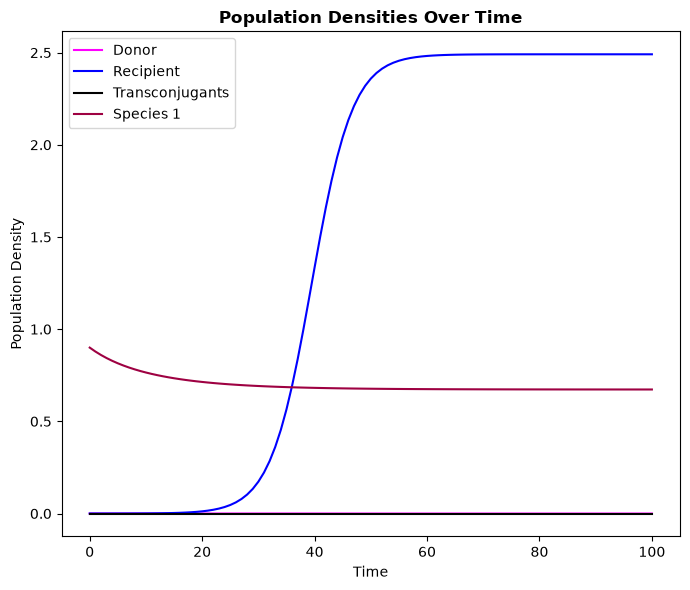

In [5]:
# --- PARAMETERS FOR DIRECT SELECTION AGAINST DONOR ---
susceptibility = [0.5, 0.05, 0.05, 0.05]      # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0.5                           # magnitude of perturbation, between 0 and 1

# --- MODEL FOR DIRECT SELECTION AGAINST DONOR ---
direct_selection_donor_trans = []
repeats = 100
for r in range(repeats):
    direct_selection_donor = ode_lotka(n_species)
    direct_selection_donor.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    direct_selection_donor.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
    direct_selection_donor_trans.append(direct_selection_donor.results.y[:, -1])
direct_selection_donor.plot_results(direct_selection_donor.results.t, direct_selection_donor.results.y.T, 'Population Densities Over Time')

#### Modelling a simple 1-species community that provides no colonisation resistance and with an antibiotic that directly selects against the recipient
This is showing that the recipient is not as able to grow well and therefore there are no bacteria that can receive the plasmid and form transconjugants

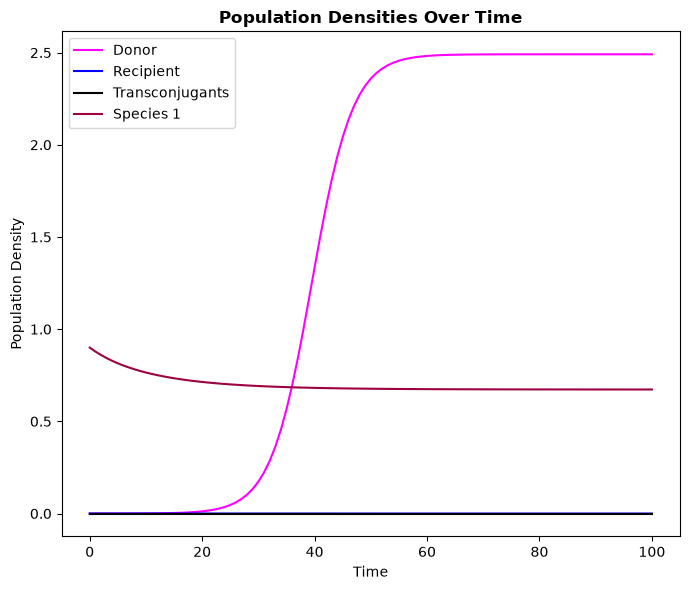

In [6]:
# --- PARAMETERS FOR DIRECT SELECTION AGAINST RECIPIENT ---
susceptibility = [0.05, 0.5, 0.05, 0.05]      # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0.5                           # magnitude of perturbation, between 0 and 1

# --- MODEL FOR DIRECT SELECTION ---
direct_selection_recip_trans = []
repeats = 100
for r in range(repeats):
    direct_selection_recip = ode_lotka(n_species)
    direct_selection_recip.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    direct_selection_recip.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
    direct_selection_recip_trans.append(direct_selection_recip.results.y[:, -1])
direct_selection_recip.plot_results(direct_selection_recip.results.t, direct_selection_recip.results.y.T, 'Population Densities Over Time')

### Modelling a simple 1-species community that provides no colonisation resistance cycling through donor and recipient susceptibilities

In [7]:
# --- SUSCEPTIBILITY ADJUSTMENTS FOR MODEL ---
donor_sus = np.linspace(0, 1, 21)          # donor susceptibility
recip_sus = np.linspace(0, 1, 21)          # recipient susceptibility
drug_level = 0.7                           # magnitude of perturbation, between 0 and 1

# --- MODEL FOR DIRECT SELECTION ---
repeats = 5
compare_selections_trans = np.zeros([len(recip_sus), len(donor_sus), repeats])
for r in range(repeats):
    print(f'\nStarting repeat {r+1}')
    compare_selections = ode_lotka(n_species)
    compare_selections.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    for ds in range(len(donor_sus)):
        print(f'Iterating through donor susceptibility {ds+1}')
        for rs in range(len(recip_sus)):
            susceptibility = [donor_sus[ds], recip_sus[rs], np.min([donor_sus[ds], recip_sus[rs]]), 0.05]
            compare_selections.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
            compare_selections_trans[rs][ds][r] = compare_selections.results.y[2, -1]
np.save(f'{datadir}/exp_no_cr_sus', compare_selections_trans)


Starting repeat 1
Iterating through donor susceptibility 1
Iterating through donor susceptibility 2
Iterating through donor susceptibility 3
Iterating through donor susceptibility 4
Iterating through donor susceptibility 5
Iterating through donor susceptibility 6
Iterating through donor susceptibility 7
Iterating through donor susceptibility 8
Iterating through donor susceptibility 9
Iterating through donor susceptibility 10
Iterating through donor susceptibility 11
Iterating through donor susceptibility 12
Iterating through donor susceptibility 13
Iterating through donor susceptibility 14
Iterating through donor susceptibility 15
Iterating through donor susceptibility 16
Iterating through donor susceptibility 17
Iterating through donor susceptibility 18
Iterating through donor susceptibility 19
Iterating through donor susceptibility 20
Iterating through donor susceptibility 21

Starting repeat 2
Iterating through donor susceptibility 1
Iterating through donor susceptibility 2
Iterati

### Comparing these simulations

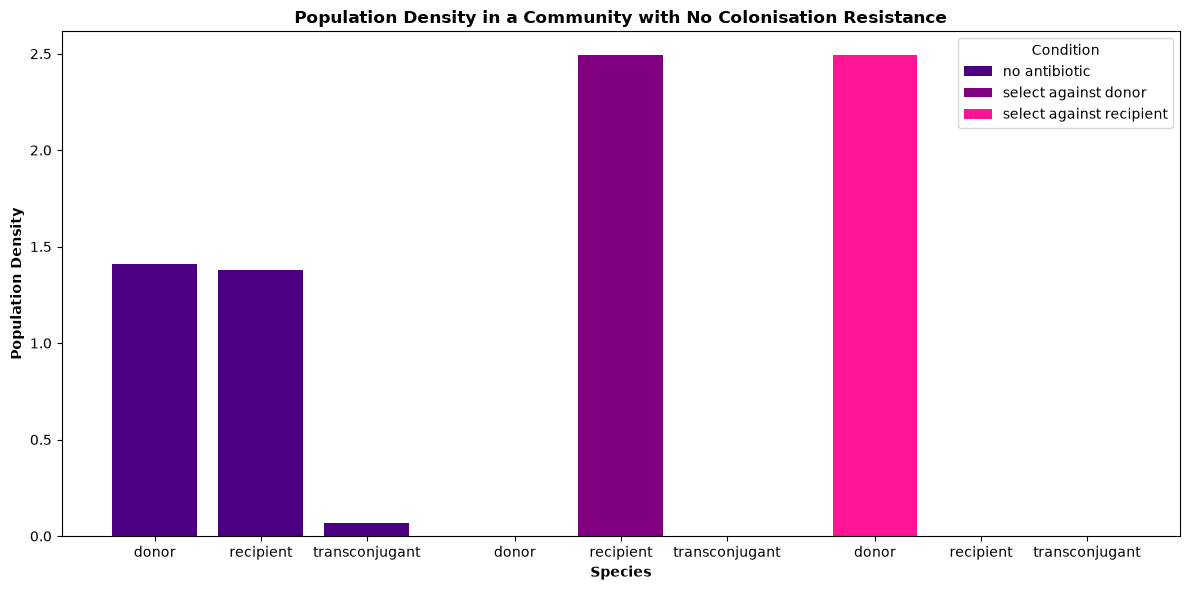

In [8]:
# --- PLOT SPECIES DENSITIES WHEN HAVING DIRECT SELECTION AGAINST DONOR ---
fig, ax = plt.subplots(figsize=(12,6))
plt.bar(x=[0.25,0.5,0.75], height=reindex_no_cr_trans[:,0:3,-1].mean(axis=0), width=0.2, label='no antibiotic', color='indigo')
plt.bar(x=[1.1,1.35,1.6], height=np.array(direct_selection_donor_trans)[:,0:3].mean(axis=0), width=0.2, label='select against donor', color='purple')
plt.bar(x=[1.95,2.2,2.45], height=np.array(direct_selection_recip_trans)[:,0:3].mean(axis=0), width=0.2, label='select against recipient', color='deeppink')
plt.title('Population Density in a Community with No Colonisation Resistance', fontweight='bold')
plt.xlabel('Species', fontweight='bold')
plt.xticks([0.25,0.5,0.75, 1.1,1.35,1.6, 1.95,2.2,2.45], labels=['donor', 'recipient', 'transconjugant', 'donor', 'recipient', 'transconjugant', 'donor', 'recipient', 'transconjugant'])
plt.ylabel('Population Density', fontweight='bold')
plt.legend(title='Condition')
plt.tight_layout()
plt.show()

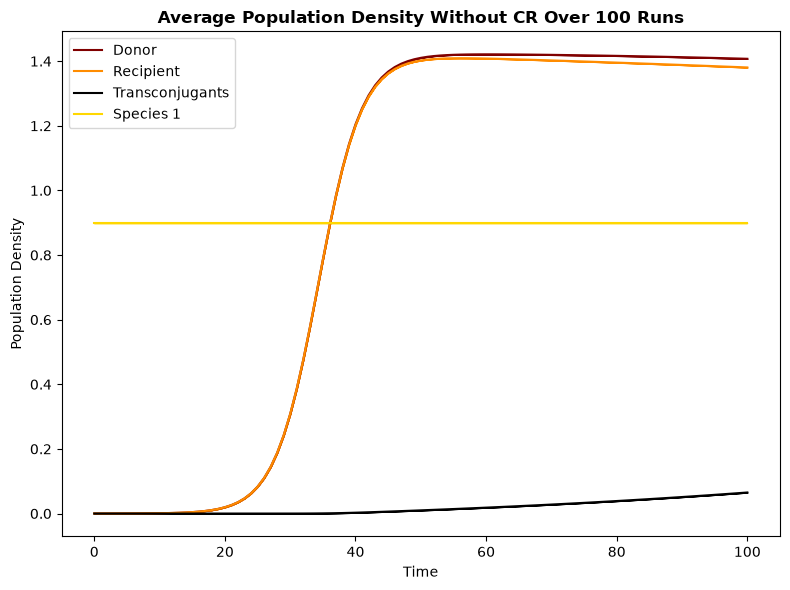

In [9]:
fig, ax = plt.subplots(figsize=(8,6))
colours = ['maroon', 'darkorange', 'black', 'gold']
labels = ['Donor', 'Recipient', 'Transconjugants', 'Species 1']
for i, (c, l) in enumerate(zip(colours, labels)):
    plt.plot(np.arange(t_start, t_end+1),
             reindex_no_cr_trans.mean(axis=0).T[:,i],
             color=c, label=l)
    plt.fill_between(np.arange(t_start, t_end+1),
                     reindex_no_cr_trans.min(axis=0)[i],
                     reindex_no_cr_trans.max(axis=0)[i],
                     color=c)
ax.set_xlabel('Time')
ax.set_ylabel('Population Density')
plt.legend()
plt.title('Average Population Density Without CR Over 100 Runs', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{figdir}/exp_nocr.png', dpi=500)
plt.show()

## Show Conjugation in a Highly Resistant Community

In [10]:
# --- PARAMETERS FOR CR ---

# Number of species to use
n_species = 1                              # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = 1                           # community connectivty (probability of interactions)
sigma = 0.6                                # interspecies interaction strength standard deviation
P_m = 0                                    # proportion of species reactions that are positive
self_inhibition = 0.1                      # intra-specific interaction strength

# Parameters for the model
conjugation_rate = 5e-4                    # average plasmid conjugation rate

# Parameters at the start of the model
t_start = 0                                # starting timestep
t_end = 100                               # ending timestep
x0 = [5e-5, 5e-5, 0, 1]                      # starting population size

### Modelling Different Selections

#### Modelling a simple 1-species community that provides colonisation resistance and no antibiotic
This is showing that the donor and recipient are able to grow to carrying capacity and transconjugants are able to form.

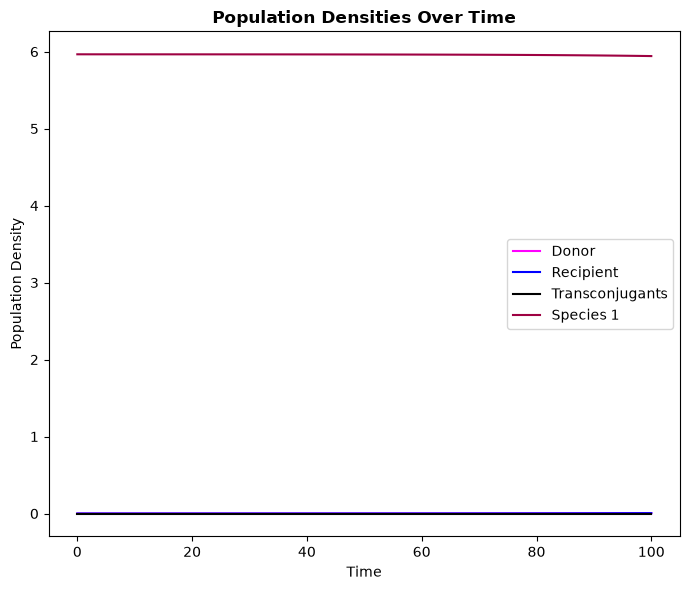

In [11]:
# --- SUSCEPTIBILITY ADJUSTMENTS FOR MODEL ---
susceptibility = [0.05, 0.05, 0.05, 0.05]      # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0                             # magnitude of perturbation, between 0 and 1

# --- MODEL FOR NO CR ---
cr_t = []
cr_trans = []
repeats = 100
for r in range(repeats):
    cr = ode_lotka(n_species)
    cr.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    cr.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
    cr_t.append(cr.results.t)
    cr_trans.append(cr.results.y)
cr.plot_results(cr.results.t, cr.results.y.T, 'Population Densities Over Time')

#### Remove CR with Antibiotics

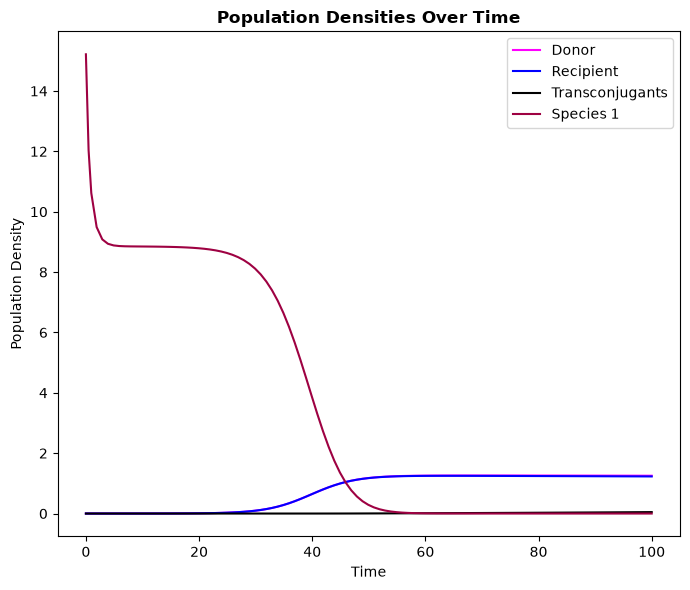

In [12]:
# --- PARAMETERS FOR REMOVING CR WITH ANTIBIOTICS ---
susceptibility = [0.05, 0.05, 0.05, 1]        # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0.7                           # magnitude of perturbation, between 0 and 1

# --- MODEL FOR REMOVE CR WITH ANTIBIOTICS ---
cr_perturb_t = []
cr_perturb_trans = []
repeats = 100
for r in range(repeats):
    cr_perturb = ode_lotka(n_species)
    cr_perturb.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    cr_perturb.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
    cr_perturb_t.append(cr_perturb.results.t)
    cr_perturb_trans.append(cr_perturb.results.y)
cr_perturb.plot_results(cr_perturb.results.t, cr_perturb.results.y.T, 'Population Densities Over Time')

#### Get Numpy Arrays

In [13]:
# --- REINDEX DATA TO FIT ---
reindex_cr_trans = []
reindex_cr_perturb_trans = []
for i in range(len(cr_perturb_t)):
    new_index = np.arange(0,t_end+1)
    # CR Run
    index_cr = cr_t[i]
    df_cr = pd.DataFrame(np.array(cr_trans[i]).T, index=index_cr)
    reindex_cr_trans.append(df_cr.reindex(index=new_index, method='nearest').to_numpy().T)
    # Perturbation Run
    index_perturb = cr_perturb_t[i]
    df_perturb = pd.DataFrame(np.array(cr_perturb_trans[i]).T, index=index_perturb)
    reindex_cr_perturb_trans.append(df_perturb.reindex(index=new_index, method='nearest').to_numpy().T)
reindex_cr_trans = np.array(reindex_cr_trans)
np.save(f'{datadir}/exp_cr_trans', reindex_cr_trans)
reindex_cr_perturb_trans = np.array(reindex_cr_perturb_trans)
np.save(f'{datadir}/exp_cr_perturb', reindex_cr_perturb_trans)

### Modelling a simple 1-species community that provides colonisation resistance cycling through donor and recipient susceptibilities

In [14]:
# --- SUSCEPTIBILITY ADJUSTMENTS FOR MODEL ---
donor_sus = np.linspace(0, 1, 21)          # donor susceptibility
recip_sus = np.linspace(0, 1, 21)          # recipient susceptibility
drug_level = 0.7                           # magnitude of perturbation, between 0 and 1

# --- MODEL FOR DIRECT SELECTION WITH A NOT VERY SUSCEPTIBLE COMMUNITY ---
repeats = 5
cr_compare_selections_trans = np.zeros([len(recip_sus), len(donor_sus), repeats])
for r in range(repeats):
    print(f'\nStarting repeat {r+1}')
    cr_compare_selections = ode_lotka(n_species)
    cr_compare_selections.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    for ds in range(len(donor_sus)):
        print(f'Iterating through donor susceptibility {ds+1}')
        for rs in range(len(recip_sus)):
            susceptibility = [donor_sus[ds], recip_sus[rs], np.min([donor_sus[ds], recip_sus[rs]]), 0.05]
            cr_compare_selections.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
            cr_compare_selections_trans[rs][ds][r] = cr_compare_selections.results.y[2, -1]
np.save(f'{datadir}/exp_cr_sus', compare_selections_trans)


Starting repeat 1
Iterating through donor susceptibility 1
Iterating through donor susceptibility 2
Iterating through donor susceptibility 3
Iterating through donor susceptibility 4
Iterating through donor susceptibility 5
Iterating through donor susceptibility 6
Iterating through donor susceptibility 7
Iterating through donor susceptibility 8
Iterating through donor susceptibility 9
Iterating through donor susceptibility 10
Iterating through donor susceptibility 11
Iterating through donor susceptibility 12
Iterating through donor susceptibility 13
Iterating through donor susceptibility 14
Iterating through donor susceptibility 15
Iterating through donor susceptibility 16
Iterating through donor susceptibility 17
Iterating through donor susceptibility 18
Iterating through donor susceptibility 19
Iterating through donor susceptibility 20
Iterating through donor susceptibility 21

Starting repeat 2
Iterating through donor susceptibility 1
Iterating through donor susceptibility 2
Iterati

In [15]:
# --- SUSCEPTIBILITY ADJUSTMENTS FOR MODEL ---
donor_sus = np.linspace(0, 1, 21)          # donor susceptibility
recip_sus = np.linspace(0, 1, 21)          # recipient susceptibility
drug_level = 0.7                           # magnitude of perturbation, between 0 and 1

# --- MODEL FOR DIRECT SELECTION WITH A VERY SUSCEPTIBLE COMMUNITY ---
repeats = 5
cr_recover_trans = np.zeros([len(recip_sus), len(donor_sus), repeats])
for r in range(repeats):
    print(f'\nStarting repeat {r+1}')
    cr_recover = ode_lotka(n_species)
    cr_recover.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    for ds in range(len(donor_sus)):
        print(f'Iterating through donor susceptibility {ds+1}')
        for rs in range(len(recip_sus)):
            susceptibility = [donor_sus[ds], recip_sus[rs], np.min([donor_sus[ds], recip_sus[rs]]), 1]
            cr_recover.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
            cr_recover_trans[rs][ds][r] = cr_recover.results.y[2, -1]
np.save(f'{datadir}/exp_cr_perturb_sus', compare_selections_trans)


Starting repeat 1
Iterating through donor susceptibility 1
Iterating through donor susceptibility 2
Iterating through donor susceptibility 3
Iterating through donor susceptibility 4
Iterating through donor susceptibility 5
Iterating through donor susceptibility 6
Iterating through donor susceptibility 7
Iterating through donor susceptibility 8
Iterating through donor susceptibility 9
Iterating through donor susceptibility 10
Iterating through donor susceptibility 11
Iterating through donor susceptibility 12
Iterating through donor susceptibility 13
Iterating through donor susceptibility 14
Iterating through donor susceptibility 15
Iterating through donor susceptibility 16
Iterating through donor susceptibility 17
Iterating through donor susceptibility 18
Iterating through donor susceptibility 19
Iterating through donor susceptibility 20
Iterating through donor susceptibility 21

Starting repeat 2
Iterating through donor susceptibility 1
Iterating through donor susceptibility 2
Iterati

### Comparing these simulations

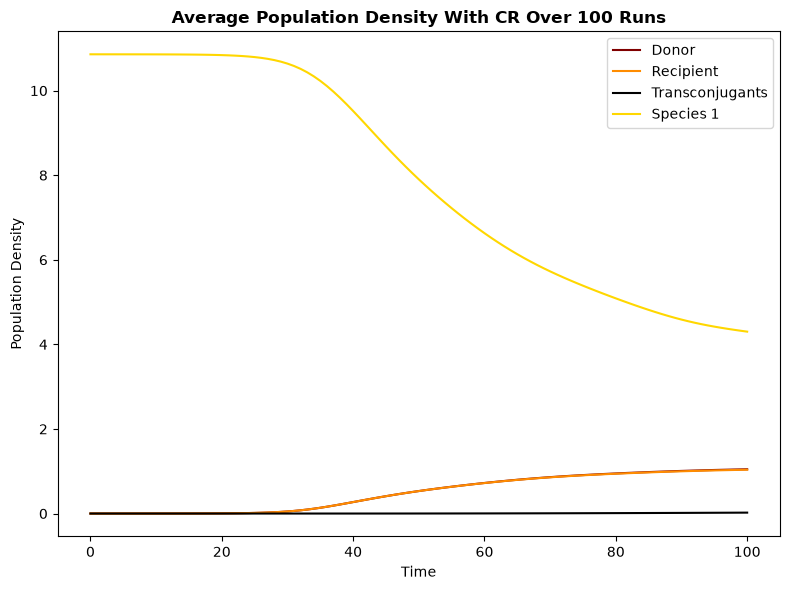

In [16]:
fig, ax = plt.subplots(figsize=(8,6))
colours = ['maroon', 'darkorange', 'black', 'gold']
labels = ['Donor', 'Recipient', 'Transconjugants', 'Species 1']
for i, (c, l) in enumerate(zip(colours, labels)):
    plt.plot(np.arange(t_start, t_end+1),
             reindex_cr_trans.mean(axis=0).T[:,i],
             color=c, label=l)
ax.set_xlabel('Time')
ax.set_ylabel('Population Density')
plt.legend()
plt.title('Average Population Density With CR Over 100 Runs', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{figdir}/exp_cr.png', dpi=500)
plt.show()

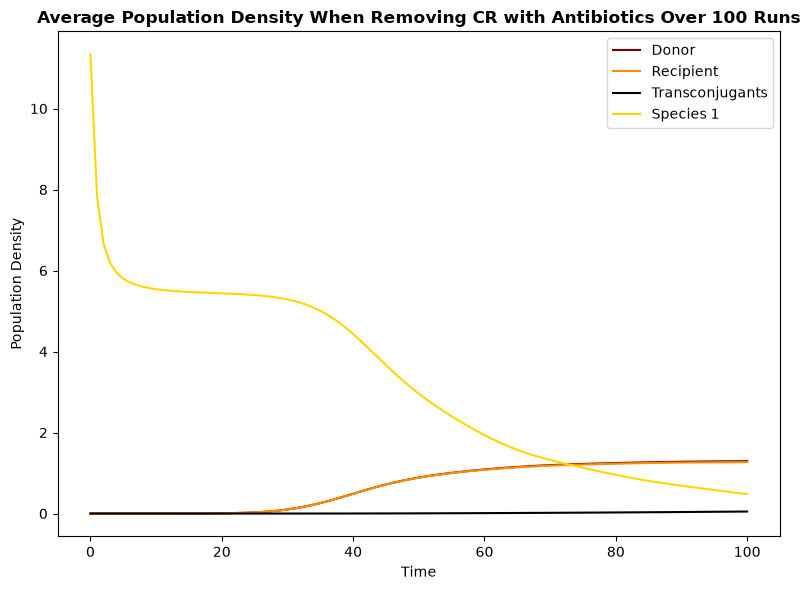

In [17]:
fig, ax = plt.subplots(figsize=(8,6))
colours = ['maroon', 'darkorange', 'black', 'gold']
labels = ['Donor', 'Recipient', 'Transconjugants', 'Species 1']
for i, (c, l) in enumerate(zip(colours, labels)):
    plt.plot(np.arange(t_start, t_end+1),
             reindex_cr_perturb_trans.mean(axis=0).T[:,i],
             color=c, label=l)
ax.set_xlabel('Time')
ax.set_ylabel('Population Density')
plt.legend()
plt.title('Average Population Density When Removing CR with Antibiotics Over 100 Runs', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{figdir}/exp_cr_perturb.png', dpi=500)
plt.show()

## Compare Community With and Without Colonisation Resistance

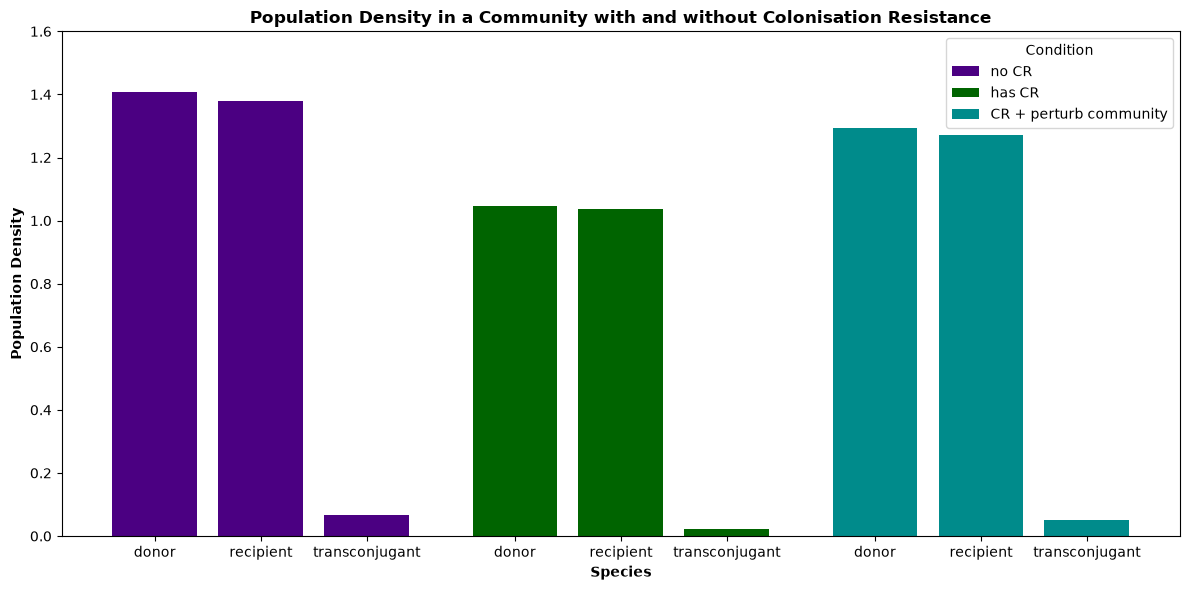

In [18]:
# --- PLOT SPECIES DENSITIES WHEN HAVING DIRECT SELECTION AGAINST DONOR ---
fig, ax = plt.subplots(figsize=(12,6))
plt.bar(x=[0.25,0.5,0.75], height=reindex_no_cr_trans[:,0:3,-1].mean(axis=0), width=0.2, label='no CR', color='indigo')
plt.bar(x=[1.1,1.35,1.6], height=reindex_cr_trans[:,0:3,-1].mean(axis=0), width=0.2, label='has CR', color='darkgreen')
plt.bar(x=[1.95,2.2,2.45], height=reindex_cr_perturb_trans[:,0:3,-1].mean(axis=0), width=0.2, label='CR + perturb community', color='darkcyan')
plt.title('Population Density in a Community with and without Colonisation Resistance', fontweight='bold')
plt.xlabel('Species', fontweight='bold')
plt.xticks([0.25,0.5,0.75, 1.1,1.35,1.6, 1.95,2.2,2.45], labels=['donor', 'recipient', 'transconjugant', 'donor', 'recipient', 'transconjugant', 'donor', 'recipient', 'transconjugant'])
plt.ylabel('Population Density', fontweight='bold')
plt.ylim(0,1.6)
plt.legend(title='Condition')
plt.tight_layout()
plt.savefig(f'{figdir}/exp_changeCR_compare.png', dpi=500)
plt.show()

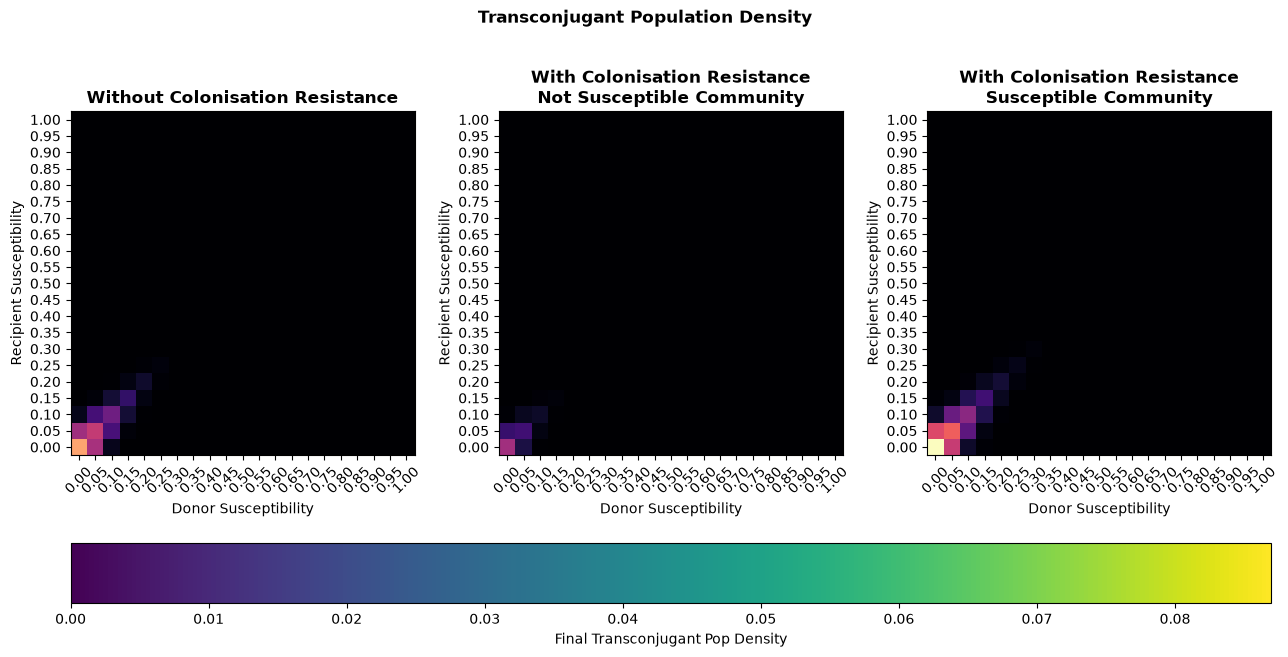

In [19]:
# --- COMPARING ALL OF THE DONOR AND RECIPIENT SUSCEPTIBILITIES ---
fig, ax = plt.subplots(1,3, figsize=(13,6.5))
normalizer = Normalize(np.min([compare_selections_trans.mean(axis=2),cr_compare_selections_trans.mean(axis=2),cr_recover_trans.mean(axis=2)]), np.max([compare_selections_trans.mean(axis=2),cr_compare_selections_trans.mean(axis=2),cr_recover_trans.mean(axis=2)]))
im = cm.ScalarMappable(norm=normalizer)

ax[0].imshow(compare_selections_trans.mean(axis=2), cmap='magma', norm=normalizer)
ax[0].set_xlabel('Donor Susceptibility')
ax[0].set_xlim(-0.5, 20.5)
ax[0].set_xticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in donor_sus.tolist()], rotation=45)
ax[0].set_ylabel('Recipient Susceptibility')
ax[0].set_ylim(-0.5,20.5)
ax[0].set_yticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in recip_sus.tolist()])
ax[0].set_title('Without Colonisation Resistance', fontweight='bold')

ax[1].imshow(cr_compare_selections_trans.mean(axis=2), cmap='magma', norm=normalizer)
ax[1].set_xlabel('Donor Susceptibility')
ax[1].set_xlim(-0.5, 20.5)
ax[1].set_xticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in donor_sus.tolist()], rotation=45)
ax[1].set_ylabel('Recipient Susceptibility')
ax[1].set_ylim(-0.5,20.5)
ax[1].set_yticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in recip_sus.tolist()])
ax[1].set_title('With Colonisation Resistance\nNot Susceptible Community', fontweight='bold')

ax[2].imshow(cr_recover_trans.mean(axis=2), cmap='magma', norm=normalizer)
ax[2].set_xlabel('Donor Susceptibility')
ax[2].set_xlim(-0.5, 20.5)
ax[2].set_xticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in donor_sus.tolist()], rotation=45)
ax[2].set_ylabel('Recipient Susceptibility')
ax[2].set_ylim(-0.5,20.5)
ax[2].set_yticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in recip_sus.tolist()])
ax[2].set_title('With Colonisation Resistance\nSusceptible Community', fontweight='bold')

plt.suptitle('Transconjugant Population Density', fontweight='bold')
plt.tight_layout()
fig.colorbar(im, ax=ax.ravel().tolist(), orientation='horizontal', label='Final Transconjugant Pop Density')
plt.savefig(f'{figdir}/exp_changeCR_sus.png', dpi=500)
plt.show()

## Vary Community Composition with 2 Species with Differing Susceptibiltiies and Interactions

- Species Aa - does not interact with *E. coli* and is ciprofloxacin susceptible => substituted for Species Ab which also does not interact with *E. coli* but is ciprofloxacin resistant
- Species Ba - interacts with *E. coli* and is ciprofloxacin susceptible => substituted for Species Bb which interacts with *E. coli* but is ciprofloxacin resistant